# Práctica 2: Regresión Logística, SVM y Análisis ROC

## Apartado 1: Regresión Logística propia

En este apartado se utiliza una implementación propia de la regresión logística binaria mediante descenso de gradiente iterativo. Se prueban distintos valores de la constante de aprendizaje y del número de pasos, utilizando los conjuntos de datos fuga telefonía y WDBC con datos estandarizados y sin estandarizar.

In [15]:
import sys
from pathlib import Path
import copy
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path('.').resolve().parent / 'MyScikitLearn'))

from datos import Datos
from particionado import ValidacionSimple
from clasificador import ClasificadorRegresionLogistica

ruta = Path('.').resolve().parent / 'datasets'
fuga = Datos(ruta / 'fuga_telefonia.csv')
wdbc = Datos(ruta / 'wdbc.csv')

val_simple = ValidacionSimple(porcentajeTrain=0.8, numParticiones=5, seed=42)

def datos_particion(datos, particion, estandarizado=False):
    datos_utilizados = datos
    if estandarizado:
        datos_utilizados = copy.deepcopy(datos)
        datos_utilizados.estandarizarDatos(indices=particion.indicesTrain)

    datos_train = datos_utilizados.datos_numericos.iloc[particion.indicesTrain]
    datos_test = datos_utilizados.datos_numericos.iloc[particion.indicesTest]
    return datos_train, datos_test

def errores_particiones(datos, particiones, tasa, pasos, estandarizado):
    errores = []

    for particion in particiones:
        datos_train, datos_test = datos_particion(datos, particion, estandarizado)
        clasificador = ClasificadorRegresionLogistica(tasaAprendizaje=tasa, pasos=pasos)
        clasificador.entrenamiento(datos_train.drop(columns=['Class']), datos_train['Class'])
        predicciones = clasificador.clasifica(datos_test.drop(columns=['Class']))
        errores.append(clasificador.error(datos_test['Class'], predicciones))

    return errores

In [16]:
tasas = [0.001, 0.01, 0.1]
pasos = [100, 500, 1000]
resultados = []

for datos, nombre in [(fuga, 'Fuga telefonia'), (wdbc, 'WDBC')]:
    particiones = val_simple.crearParticiones(datos.datos_numericos)

    for tasa in tasas:
        for numero_pasos in pasos:
            for estandarizado in [False, True]:
                errores = errores_particiones(
                    datos, particiones, tasa, numero_pasos, estandarizado
                )
                resultados.append({
                    'Dataset': nombre,
                    'Tasa aprendizaje': tasa,
                    'Pasos': numero_pasos,
                    'Estandarizado': 'Si' if estandarizado else 'No',
                    'Error medio': np.mean(errores),
                    'Desviacion tipica': np.std(errores)
                })

resultados = pd.DataFrame(resultados)
resultados

,Dataset,Tasa aprendizaje,Pasos,Estandarizado,Error medio,Desviacion tipica
0,Fuga telefonia,0.001,100,No,0.479630,0.019988
1,Fuga telefonia,0.001,100,Si,0.337037,0.019510
2,Fuga telefonia,0.001,500,No,0.438889,0.013858
3,Fuga telefonia,0.001,500,Si,0.334259,0.020580
4,Fuga telefonia,0.001,1000,No,0.433333,0.020621
5,Fuga telefonia,0.001,1000,Si,0.333333,0.021316
6,Fuga telefonia,0.010,100,No,0.479630,0.019988
7,Fuga telefonia,0.010,100,Si,0.333333,0.021316
8,Fuga telefonia,0.010,500,No,0.438889,0.013858
9,Fuga telefonia,0.010,500,Si,0.328704,0.020910


Hemos comprobado que la estandarización mejora claramente los resultados. En `fuga_telefonia`, el mejor error es aproximadamente 0.304, utilizando una tasa de aprendizaje de 0.1 y 1000 pasos. En `wdbc`, el mejor resultado es aproximadamente 0.011 con la misma tasa y el mismo número de pasos. Sin estandarizar, los errores son bastante mayores. También observamos que aumentar el número de pasos mejora los resultados cuando los datos están estandarizados, porque los pesos tienen más tiempo para ajustarse.

## Apartado 2: Regresión Logística con Scikit-Learn

Hemos comparado los resultados de `LogisticRegression` y `SGDClassifier` con el mejor resultado obtenido en nuestra implementación propia. Hemos probado ambos algoritmos en los dos conjuntos de datos y con datos estandarizados y sin estandarizar.

In [17]:
from sklearn.linear_model import LogisticRegression, SGDClassifier

def errores_sklearn(datos, particiones, algoritmo, estandarizado):
    errores = []

    for particion in particiones:
        datos_train, datos_test = datos_particion(datos, particion, estandarizado)
        x_train = datos_train.drop(columns=['Class'])
        y_train = datos_train['Class']
        x_test = datos_test.drop(columns=['Class'])
        y_test = datos_test['Class']

        if algoritmo == 'LogisticRegression':
            clasificador = LogisticRegression(
                solver='liblinear', max_iter=1000, random_state=42
            )
        else:
            clasificador = SGDClassifier(
                loss='log_loss', max_iter=1000, random_state=42
            )

        clasificador.fit(x_train, y_train)
        predicciones = clasificador.predict(x_test)
        errores.append(np.mean(predicciones != y_test))

    return errores

In [18]:
resultados_sklearn = []

for datos, nombre in [(fuga, 'Fuga telefonia'), (wdbc, 'WDBC')]:
    particiones = val_simple.crearParticiones(datos.datos_numericos)

    for algoritmo in ['LogisticRegression', 'SGDClassifier']:
        for estandarizado in [False, True]:
            errores = errores_sklearn(
                datos, particiones, algoritmo, estandarizado
            )
            resultados_sklearn.append({
                'Dataset': nombre,
                'Algoritmo': algoritmo,
                'Estandarizado': 'Si' if estandarizado else 'No',
                'Error medio': np.mean(errores),
                'Desviacion tipica': np.std(errores)
            })

resultados_sklearn = pd.DataFrame(resultados_sklearn)
resultados_sklearn

,Dataset,Algoritmo,Estandarizado,Error medio,Desviacion tipica
0,Fuga telefonia,LogisticRegression,No,0.362963,0.049222
1,Fuga telefonia,LogisticRegression,Si,0.304630,0.020787
2,Fuga telefonia,SGDClassifier,No,0.448148,0.044924
3,Fuga telefonia,SGDClassifier,Si,0.317593,0.021636
4,WDBC,LogisticRegression,No,0.040351,0.023275
5,WDBC,LogisticRegression,Si,0.010526,0.006564
6,WDBC,SGDClassifier,No,0.170175,0.073307
7,WDBC,SGDClassifier,Si,0.026316,0.014678


In [19]:
mejores_propio = resultados.loc[
    resultados.groupby(['Dataset', 'Estandarizado'])['Error medio'].idxmin()
].copy()
mejores_propio['Algoritmo'] = 'Regresion Logistica propia'
mejores_propio = mejores_propio[
    ['Dataset', 'Algoritmo', 'Estandarizado', 'Error medio', 'Desviacion tipica']
]

comparacion = pd.concat([mejores_propio, resultados_sklearn], ignore_index=True)
comparacion

,Dataset,Algoritmo,Estandarizado,Error medio,Desviacion tipica
0,Fuga telefonia,Regresion Logistica propia,No,0.433333,0.020621
1,Fuga telefonia,Regresion Logistica propia,Si,0.303704,0.022414
2,WDBC,Regresion Logistica propia,No,0.122807,0.095288
3,WDBC,Regresion Logistica propia,Si,0.010526,0.010230
4,Fuga telefonia,LogisticRegression,No,0.362963,0.049222
5,Fuga telefonia,LogisticRegression,Si,0.304630,0.020787
6,Fuga telefonia,SGDClassifier,No,0.448148,0.044924
7,Fuga telefonia,SGDClassifier,Si,0.317593,0.021636
8,WDBC,LogisticRegression,No,0.040351,0.023275
9,WDBC,LogisticRegression,Si,0.010526,0.006564


`LogisticRegression` utiliza el solucionador `liblinear`, apropiado para este problema binario, y se fija `max_iter=1000` para permitir que el entrenamiento termine correctamente. En `SGDClassifier` se utiliza `loss='log_loss'` para aplicar regresión logística mediante descenso de gradiente, con `max_iter=1000`. En ambos casos se fija `random_state=42` para mantener las particiones y los resultados reproducibles.

En `fuga_telefonia`, `LogisticRegression` obtiene el mejor resultado de Scikit-Learn cuando estandarizamos los datos, con un error aproximado de 0.305. Este resultado es muy parecido al de nuestra implementación propia, que obtiene aproximadamente 0.304. `SGDClassifier` funciona algo peor, con un error aproximado de 0.318.

En `wdbc`, `LogisticRegression` estandarizado y nuestra implementación propia obtienen ambos un error aproximado de 0.011. `SGDClassifier` también mejora al estandarizar, aunque su error es algo mayor, aproximadamente 0.026. Las diferencias se deben a que cada algoritmo utiliza un método de optimización y unos parámetros internos distintos. En todos los casos hemos utilizado las mismas particiones para poder comparar los resultados.

## Apartado 3: SVM y ajuste de parámetros

Hemos utilizado los algoritmos `SVC` y `LinearSVC` de Scikit-Learn. El ajuste de parámetros se realiza con `GridSearchCV` únicamente sobre el conjunto de entrenamiento. Después evaluamos el mejor modelo sobre el conjunto de test. También hemos probado los datos estandarizados y sin estandarizar porque los algoritmos SVM dependen de la escala de los atributos.

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC, LinearSVC

def evaluar_svm(datos, particiones, algoritmo, estandarizado):
    errores = []
    mejores_parametros = []

    for particion in particiones:
        datos_train, datos_test = datos_particion(datos, particion, estandarizado)
        x_train = datos_train.drop(columns=['Class'])
        y_train = datos_train['Class']
        x_test = datos_test.drop(columns=['Class'])
        y_test = datos_test['Class']

        if algoritmo == 'SVC':
            modelo = SVC()
            parametros = {
                'C': [0.1, 1, 10],
                'gamma': ['scale', 'auto']
            }
        else:
            modelo = LinearSVC(max_iter=5000, random_state=42)
            parametros = {
                'C': [0.1, 1, 10]
            }

        ajuste = GridSearchCV(modelo, parametros, cv=5)
        ajuste.fit(x_train, y_train)
        predicciones = ajuste.predict(x_test)

        errores.append(np.mean(predicciones != y_test))
        mejores_parametros.append(str(ajuste.best_params_))

    return errores, mejores_parametros

In [21]:
resultados_svm = []

for datos, nombre in [(fuga, 'Fuga telefonia'), (wdbc, 'WDBC')]:
    particiones = val_simple.crearParticiones(datos.datos_numericos)

    for algoritmo in ['SVC', 'LinearSVC']:
        for estandarizado in [False, True]:
            errores, mejores_parametros = evaluar_svm(
                datos, particiones, algoritmo, estandarizado
            )
            resultados_svm.append({
                'Dataset': nombre,
                'Algoritmo': algoritmo,
                'Estandarizado': 'Si' if estandarizado else 'No',
                'Mejores parametros': ', '.join(mejores_parametros),
                'Error medio': np.mean(errores),
                'Desviacion tipica': np.std(errores)
            })

resultados_svm = pd.DataFrame(resultados_svm)
resultados_svm

,Dataset,Algoritmo,Estandarizado,Mejores parametros,Error medio,Desviacion tipica
0,Fuga telefonia,SVC,No,"{'C': 0.1, 'gamma': 'scale'}, {'C': 1, 'gamma'...",0.466667,0.018379
1,Fuga telefonia,SVC,Si,"{'C': 10, 'gamma': 'scale'}, {'C': 10, 'gamma'...",0.283333,0.013858
2,Fuga telefonia,LinearSVC,No,"{'C': 0.1}, {'C': 0.1}, {'C': 0.1}, {'C': 1}, ...",0.410185,0.031887
3,Fuga telefonia,LinearSVC,Si,"{'C': 0.1}, {'C': 10}, {'C': 1}, {'C': 1}, {'C...",0.303704,0.022414
4,WDBC,SVC,No,"{'C': 10, 'gamma': 'scale'}, {'C': 10, 'gamma'...",0.064912,0.016270
5,WDBC,SVC,Si,"{'C': 10, 'gamma': 'scale'}, {'C': 10, 'gamma'...",0.019298,0.012892
6,WDBC,LinearSVC,No,"{'C': 1}, {'C': 1}, {'C': 1}, {'C': 10}, {'C':...",0.035088,0.020003
7,WDBC,LinearSVC,Si,"{'C': 0.1}, {'C': 0.1}, {'C': 0.1}, {'C': 0.1}...",0.014035,0.010526


En `SVC` hemos ajustado `C` y `gamma`. `C` controla la penalización de los errores y `gamma` controla la influencia de cada instancia en el modelo. En `LinearSVC` hemos ajustado `C`, que controla la penalización de los errores en el clasificador lineal. La validación cruzada utilizada por `GridSearchCV` es de cinco particiones y el conjunto de test solo se utiliza después de seleccionar los mejores parámetros.

En `fuga_telefonia`, el mejor resultado es el de `SVC` con datos estandarizados, con un error aproximado de 0.283. En `wdbc`, el mejor resultado es el de `LinearSVC` estandarizado, con un error aproximado de 0.014. En los dos conjuntos la estandarización mejora claramente los resultados.

## Apartado 4: Análisis ROC

Hemos comparado Naive Bayes, K-NN, Regresión Logística y SVM en los dos conjuntos de datos. Para Naive Bayes, K-NN y Regresión Logística hemos incluido la implementación propia y la de Scikit-Learn. Para SVM hemos utilizado la mejor implementación de Scikit-Learn obtenida en el apartado anterior. Para Naive Bayes y K-NN hemos recuperado las mejores configuraciones de la Práctica 1: Laplace para Naive Bayes y K=9 para K-NN. En K-NN hemos utilizado los datos estandarizados, tal como vimos que daba mejores resultados.

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from clasificador import ClasificadorNaiveBayes, ClasificadorKNN

In [23]:
mejores_roc = {}

for nombre in ['Fuga telefonia', 'WDBC']:
    mejores_roc[nombre] = [
        {
            'Nombre': 'Naive Bayes propio',
            'crear': lambda: ClasificadorNaiveBayes(laplace=True),
            'propio': True,
            'Estandarizado': False
        },
        {
            'Nombre': 'K-NN propio',
            'crear': lambda: ClasificadorKNN(k=9),
            'propio': True,
            'Estandarizado': True
        },
        {
            'Nombre': 'Naive Bayes Scikit-Learn',
            'crear': lambda: GaussianNB(),
            'propio': False,
            'Estandarizado': False
        },
        {
            'Nombre': 'K-NN Scikit-Learn',
            'crear': lambda: KNeighborsClassifier(n_neighbors=9),
            'propio': False,
            'Estandarizado': True
        }
    ]

In [24]:
for datos, nombre in [(fuga, 'Fuga telefonia'), (wdbc, 'WDBC')]:
    fila = resultados[resultados['Dataset'] == nombre].loc[
        resultados[resultados['Dataset'] == nombre]['Error medio'].idxmin()
    ]
    tasa = fila['Tasa aprendizaje']
    pasos_log = int(fila['Pasos'])
    mejores_roc[nombre].append({
        'Nombre': 'Regresion Logistica propia',
        'crear': lambda tasa=tasa, pasos_log=pasos_log: ClasificadorRegresionLogistica(
            tasaAprendizaje=tasa, pasos=pasos_log
        ),
        'propio': True,
        'Estandarizado': fila['Estandarizado'] == 'Si',
        'Error medio': fila['Error medio']
    })

    fila = resultados_sklearn[resultados_sklearn['Dataset'] == nombre].loc[
        resultados_sklearn[resultados_sklearn['Dataset'] == nombre]['Error medio'].idxmin()
    ]
    mejores_roc[nombre].append({
        'Nombre': 'Regresion Logistica Scikit-Learn',
        'crear': lambda: LogisticRegression(
            solver='liblinear', max_iter=1000, random_state=42
        ),
        'propio': False,
        'Estandarizado': fila['Estandarizado'] == 'Si',
        'Error medio': fila['Error medio']
    })

    fila = resultados_svm[resultados_svm['Dataset'] == nombre].loc[
        resultados_svm[resultados_svm['Dataset'] == nombre]['Error medio'].idxmin()
    ]
    mejores_roc[nombre].append({
        'Nombre': 'SVM Scikit-Learn',
        'Algoritmo': fila['Algoritmo'],
        'Estandarizado': fila['Estandarizado'] == 'Si',
        'Error medio': fila['Error medio']
    })

In [25]:
def resultados_dataset_roc(datos, configuraciones):
    particion = val_simple.crearParticiones(datos.datos_numericos)[0]
    resultados_dataset = []

    for configuracion in configuraciones:
        datos_train, datos_test = datos_particion(
            datos, particion, configuracion['Estandarizado']
        )
        x_train = datos_train.drop(columns=['Class'])
        y_train = datos_train['Class']
        x_test = datos_test.drop(columns=['Class'])
        y_test = datos_test['Class']

        if configuracion['Nombre'] == 'SVM Scikit-Learn':
            if configuracion['Algoritmo'] == 'SVC':
                modelo = GridSearchCV(
                    SVC(),
                    {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto']},
                    cv=5
                )
            else:
                modelo = GridSearchCV(
                    LinearSVC(max_iter=5000, random_state=42),
                    {'C': [0.1, 1, 10]},
                    cv=5
                )
            modelo.fit(x_train, y_train)
            predicciones = modelo.predict(x_test)
            if hasattr(modelo, 'predict_proba'):
                puntuaciones = modelo.predict_proba(x_test)[:, 1]
            else:
                puntuaciones = modelo.decision_function(x_test)
            matriz = confusion_matrix(y_test, predicciones)
        else:
            modelo = configuracion['crear']()
            if configuracion['propio']:
                modelo.entrenamiento(x_train, y_train)
                predicciones = modelo.clasifica(x_test)
                matriz = modelo.matrizConfusion(y_test, predicciones)
                if configuracion['Nombre'] == 'Regresion Logistica propia':
                    puntuaciones = modelo.probabilidades(x_test)
                else:
                    puntuaciones = np.asarray(predicciones)
            else:
                modelo.fit(x_train, y_train)
                predicciones = modelo.predict(x_test)
                matriz = confusion_matrix(y_test, predicciones)
                if hasattr(modelo, 'predict_proba'):
                    puntuaciones = modelo.predict_proba(x_test)[:, 1]
                else:
                    puntuaciones = modelo.decision_function(x_test)

        resultados_dataset.append({
            'Nombre': configuracion['Nombre'],
            'Real': np.asarray(y_test),
            'Predicciones': np.asarray(predicciones),
            'Puntuaciones': np.asarray(puntuaciones),
            'Matriz': matriz
        })

    return resultados_dataset

In [26]:
resultados_roc = {}

for datos, nombre in [(fuga, 'Fuga telefonia'), (wdbc, 'WDBC')]:
    resultados_roc[nombre] = resultados_dataset_roc(datos, mejores_roc[nombre])

matrices_roc = []
for nombre, resultados_dataset in resultados_roc.items():
    for resultado in resultados_dataset:
        tn, fp, fn, tp = resultado['Matriz'].ravel()
        matrices_roc.append({
            'Dataset': nombre,
            'Clasificador': resultado['Nombre'],
            'TP': tp,
            'FP': fp,
            'FN': fn,
            'TN': tn,
            'TPR': tp / (tp + fn),
            'FNR': fn / (tp + fn),
            'FPR': fp / (fp + tn),
            'TNR': tn / (fp + tn)
        })

matrices_roc = pd.DataFrame(matrices_roc)
matrices_roc

,Dataset,Clasificador,TP,FP,FN,TN,TPR,FNR,FPR,TNR
0,Fuga telefonia,Naive Bayes propio,55,17,53,91,0.509259,0.490741,0.157407,0.842593
1,Fuga telefonia,K-NN propio,68,25,40,83,0.629630,0.370370,0.231481,0.768519
2,Fuga telefonia,Naive Bayes Scikit-Learn,62,28,46,80,0.574074,0.425926,0.259259,0.740741
3,Fuga telefonia,K-NN Scikit-Learn,68,25,40,83,0.629630,0.370370,0.231481,0.768519
4,Fuga telefonia,Regresion Logistica propia,76,27,32,81,0.703704,0.296296,0.250000,0.750000
5,Fuga telefonia,Regresion Logistica Scikit-Learn,76,29,32,79,0.703704,0.296296,0.268519,0.731481
6,Fuga telefonia,SVM Scikit-Learn,76,29,32,79,0.703704,0.296296,0.268519,0.731481
7,WDBC,Naive Bayes propio,40,4,2,68,0.952381,0.047619,0.055556,0.944444
8,WDBC,K-NN propio,39,1,3,71,0.928571,0.071429,0.013889,0.986111
9,WDBC,Naive Bayes Scikit-Learn,39,2,3,70,0.928571,0.071429,0.027778,0.972222


Hemos calculado una matriz de confusión para cada clasificador y para cada conjunto de datos. A partir de TP, FP, FN y TN hemos obtenido las tasas TPR, FNR, FPR y TNR que utilizaremos para colocar cada clasificador en el Espacio ROC.

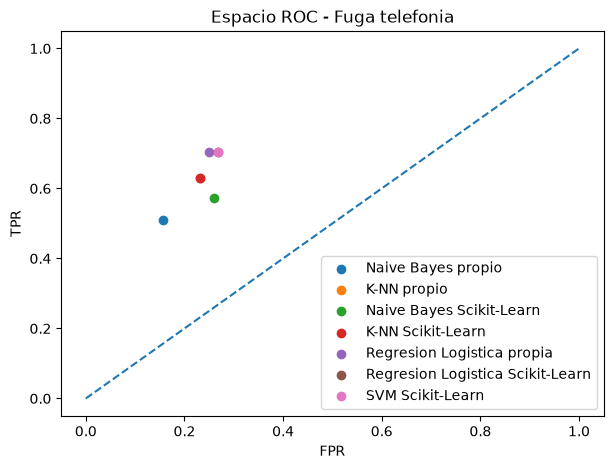

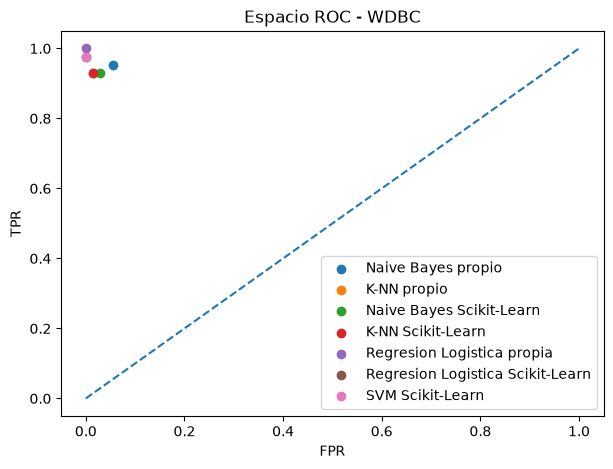

In [27]:
for nombre, resultados_dataset in resultados_roc.items():
    plt.figure(figsize=(7, 5))
    for resultado in resultados_dataset:
        fila = matrices_roc[
            (matrices_roc['Dataset'] == nombre) &
            (matrices_roc['Clasificador'] == resultado['Nombre'])
        ].iloc[0]
        plt.scatter(fila['FPR'], fila['TPR'], label=resultado['Nombre'])

    plt.plot([0, 1], [0, 1], '--')
    plt.xlabel('FPR')
    plt.ylabel('TPR')
    plt.title('Espacio ROC - ' + nombre)
    plt.legend()
    plt.show()

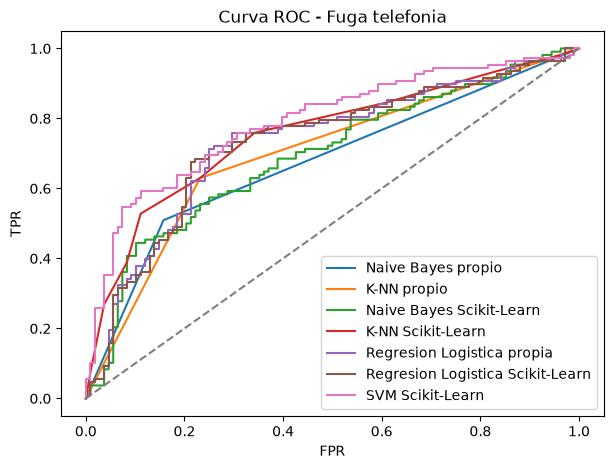

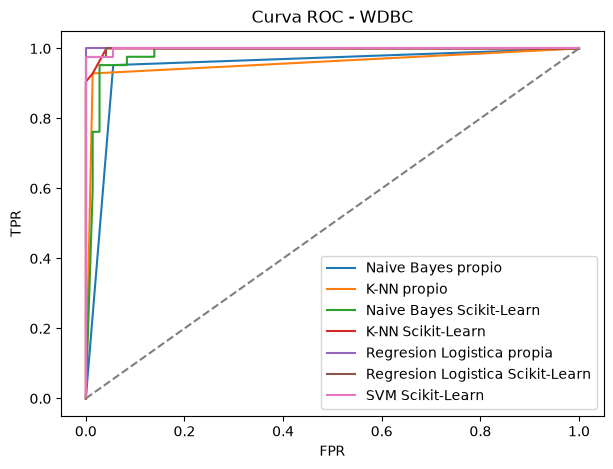

,Dataset,Clasificador,AUC
0,Fuga telefonia,Naive Bayes propio,0.675926
1,Fuga telefonia,K-NN propio,0.699074
2,Fuga telefonia,Naive Bayes Scikit-Learn,0.693544
3,Fuga telefonia,K-NN Scikit-Learn,0.754201
4,Fuga telefonia,Regresion Logistica propia,0.731224
5,Fuga telefonia,Regresion Logistica Scikit-Learn,0.730881
6,Fuga telefonia,SVM Scikit-Learn,0.789952
7,WDBC,Naive Bayes propio,0.948413
8,WDBC,K-NN propio,0.957341
9,WDBC,Naive Bayes Scikit-Learn,0.982970


In [28]:
auc_roc = []

for nombre, resultados_dataset in resultados_roc.items():
    plt.figure(figsize=(7, 5))
    for resultado in resultados_dataset:
        fpr, tpr, _ = roc_curve(
            resultado['Real'], resultado['Puntuaciones']
        )
        auc = roc_auc_score(
            resultado['Real'], resultado['Puntuaciones']
        )
        auc_roc.append({
            'Dataset': nombre,
            'Clasificador': resultado['Nombre'],
            'AUC': auc
        })
        plt.plot(fpr, tpr, label=resultado['Nombre'])

    plt.plot([0, 1], [0, 1], '--')
    plt.xlabel('FPR')
    plt.ylabel('TPR')
    plt.title('Curva ROC - ' + nombre)
    plt.legend()
    plt.show()

auc_roc = pd.DataFrame(auc_roc)
auc_roc

El Espacio ROC nos permite comparar los clasificadores observando cuántos positivos detectan y cuántos falsos positivos producen. En `fuga_telefonia`, la Regresión Logística propia y la de Scikit-Learn obtienen el mismo TPR, 0.704 aproximadamente, aunque la implementación propia tiene un FPR algo menor, 0.250 frente a 0.269. SVM obtiene también un TPR de 0.704, pero con el mismo FPR que la Regresión Logística de Scikit-Learn. Naive Bayes propio produce menos falsos positivos, con un FPR de 0.157, pero también detecta menos positivos, con un TPR de 0.509. Por tanto, en este conjunto no hay un punto que sea mejor en todos los aspectos.

En `wdbc`, los resultados son mejores para todos los clasificadores. La Regresión Logística propia consigue TPR = 1.000 y FPR = 0.000 en la partición utilizada. La Regresión Logística de Scikit-Learn y SVM también tienen FPR = 0.000, aunque su TPR es ligeramente menor, 0.976. K-NN de Scikit-Learn tiene un FPR muy bajo, 0.014, y un TPR de 0.929. Esto muestra que `wdbc` resulta más fácil de clasificar que `fuga_telefonia`.

En las Curvas ROC hemos utilizado `roc_curve` y hemos calculado el área bajo cada curva con `roc_auc_score`. En `fuga_telefonia`, el mejor AUC es el de SVM, con 0.790, seguido de K-NN de Scikit-Learn, con 0.754. La Regresión Logística propia y la de Scikit-Learn tienen valores muy parecidos, 0.731 y 0.731, mientras que Naive Bayes propio obtiene el valor más bajo, 0.676.

En `wdbc`, todos los valores AUC son altos. La Regresión Logística propia obtiene el mejor resultado, con 1.000. K-NN de Scikit-Learn alcanza 0.998, SVM 0.999 y la Regresión Logística de Scikit-Learn 0.999. Naive Bayes también funciona bien, aunque su AUC es algo menor. En conjunto, hemos comprobado que los clasificadores funcionan mejor en `wdbc` y que SVM y la Regresión Logística son los que mejores resultados ofrecen al comparar el AUC.

Para los clasificadores propios que solo devuelven la clase hemos obtenido un punto en el Espacio ROC. Para dibujar las curvas hemos utilizado sus predicciones como puntuación, mientras que los modelos de Scikit-Learn utilizan sus probabilidades o su función de decisión.